# 03 · Tyre degradation model

Plots and tables only. The model, fitting and evaluation code is in
`f1strat.deg_model`; the spec is `docs/model.md`.

Fits are loaded from `models/`. Rebuild them with
`uv run python -m f1strat.deg_model all`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from f1strat.clean import clean_laps
from f1strat.data import load_season
from f1strat.deg_model import (
    FULL_FIT_PATH, SPLITS, comparison_table, deg_by_race, deg_curve, effects_table,
    error_by_tyre_age, stint_team_confounding, interval_widening_factor,
    fit_xgboost, load_fit, predict, predict_baseline, fit_baseline, predict_xgboost,
    prepare, season_deg_table, split_fit_path, team_compound_summary,
)

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

COMPOUND_COLORS = {"SOFT": "#d9342b", "MEDIUM": "#eda100", "HARD": "#2a78d6"}
MODEL_COLORS = {"Baseline (OLS)": "#52514e", "XGBoost": "#eb6834", "Bayesian": "#2a78d6"}
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "savefig.dpi": 150, "savefig.bbox": "tight",
})

laps = prepare(clean_laps(load_season(2022)))
full = load_fit(FULL_FIT_PATH)
split_fits = {name: load_fit(split_fit_path(name)) for name in SPLITS}
event = laps.groupby("RoundNumber")["EventName"].first().str.replace(" Grand Prix", "")
for name, f in {"full": full, **split_fits}.items():
    print(name, f.diagnostics)

full {'max_r_hat': 1.0083031844598147, 'min_ess_bulk': 605.988922898101, 'min_ess_tail': 719.1728000912551, 'divergences': 0}
last_stint {'max_r_hat': 1.008893265429176, 'min_ess_bulk': 732.4379427524294, 'min_ess_tail': 1170.7924177348293, 'divergences': 0}
long_tyre {'max_r_hat': 1.0056496473880552, 'min_ess_bulk': 812.3554502004833, 'min_ess_tail': 1210.769091923442, 'divergences': 0}


## Model comparison on the held-out sets

In [2]:
comp = comparison_table(laps, split_fits)
comp.to_csv(FIG_DIR / "model_comparison.csv", index=False)
comp.round(3)

,split,subset,model,mae_s,rmse_s,n_predicted,n_unpredictable,coverage_80
0,last_stint,common,baseline,0.874,1.129,2477,0,NaN
1,last_stint,common,xgboost,1.010,1.270,2477,0,NaN
2,last_stint,common,bayes,0.598,0.842,2477,0,0.738
3,last_stint,all,xgboost,1.008,1.269,2508,0,NaN
4,last_stint,all,bayes,0.600,0.846,2508,0,0.740
5,long_tyre,common,baseline,0.524,0.742,5539,0,NaN
6,long_tyre,common,xgboost,0.510,0.760,5539,0,NaN
7,long_tyre,common,bayes,0.505,0.725,5539,0,0.668
8,long_tyre,all,xgboost,0.510,0.760,5539,0,NaN
9,long_tyre,all,bayes,0.505,0.725,5539,0,0.668


### Interval widening needed on `last_stint`

Factor by which the 80% interval half-widths (around the mean) must be scaled
for 80% of held-out final-stint laps to fall inside. 1.0 means no widening is
needed. Phase 4 can apply it.

In [3]:
ls_train, ls_test = SPLITS["last_stint"](laps)
ls_pred = predict(split_fits["last_stint"], ls_test)
factor = interval_widening_factor(ls_test["lap_s"], ls_pred)
print(f"80% interval widening factor on last_stint: {factor:.3f}")

80% interval widening factor on last_stint: 1.188


## Season degradation rate per compound

Field-average car. Degradation is linear in tyre age (no cliff term); the
loss columns are the extra time after 10 and 20 laps. 80% intervals.

In [4]:
season = season_deg_table(full)
season.to_csv(FIG_DIR / "season_deg.csv", index=False)

def fmt(m, lo, hi, nd=3):
    return f"{m:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]"

table = pd.DataFrame({
    "Compound": season["compound"].str.title(),
    "Deg (s/lap)": [fmt(*r) for r in season[["deg_s_per_lap", "deg_s_per_lap_lo", "deg_s_per_lap_hi"]].to_numpy()],
    "Loss after 10 laps (s)": [fmt(*r, nd=2) for r in season[["loss_10_laps_s", "loss_10_laps_s_lo", "loss_10_laps_s_hi"]].to_numpy()],
    "Loss after 20 laps (s)": [fmt(*r, nd=2) for r in season[["loss_20_laps_s", "loss_20_laps_s_lo", "loss_20_laps_s_hi"]].to_numpy()],
})
(FIG_DIR / "season_deg.md").write_text(table.to_markdown(index=False) + "\n")
table

,Compound,Deg (s/lap),Loss after 10 laps (s),Loss after 20 laps (s)
0,Soft,"0.101 [0.077, 0.125]","1.01 [0.77, 1.25]","2.02 [1.54, 2.51]"
1,Medium,"0.075 [0.061, 0.090]","0.75 [0.61, 0.90]","1.50 [1.21, 1.80]"
2,Hard,"0.055 [0.040, 0.071]","0.55 [0.40, 0.71]","1.11 [0.80, 1.42]"


In [5]:
effects = effects_table(full)
effects.round(4)

,effect,level,unit,mean,lo,hi
0,mu_deg,SOFT,s/lap,0.1012,0.0770,0.1253
1,mu_deg,MEDIUM,s/lap,0.0752,0.0605,0.0899
2,mu_deg,HARD,s/lap,0.0553,0.0399,0.0709
3,mu_compound,SOFT,s,-0.4355,-0.5549,-0.3135
4,mu_compound,HARD,s,0.4135,0.2940,0.5329
5,post_stop,SOFT,s,0.0610,0.0120,0.1099
6,post_stop,MEDIUM,s,-0.0631,-0.0981,-0.0280
7,post_stop,HARD,s,-0.0954,-0.1267,-0.0641
8,opening,None,s,0.3504,0.3176,0.3835
9,mu_trend,None,s/lap,-0.0553,-0.0604,-0.0504


## Degradation curves per compound, with 80% bands

Tyre effect alone (compound offset + linear deg) for the field-average car,
relative to a new medium. Fuel and track trend are not included. Each curve is
drawn up to the oldest tyre age run on that compound at that race.

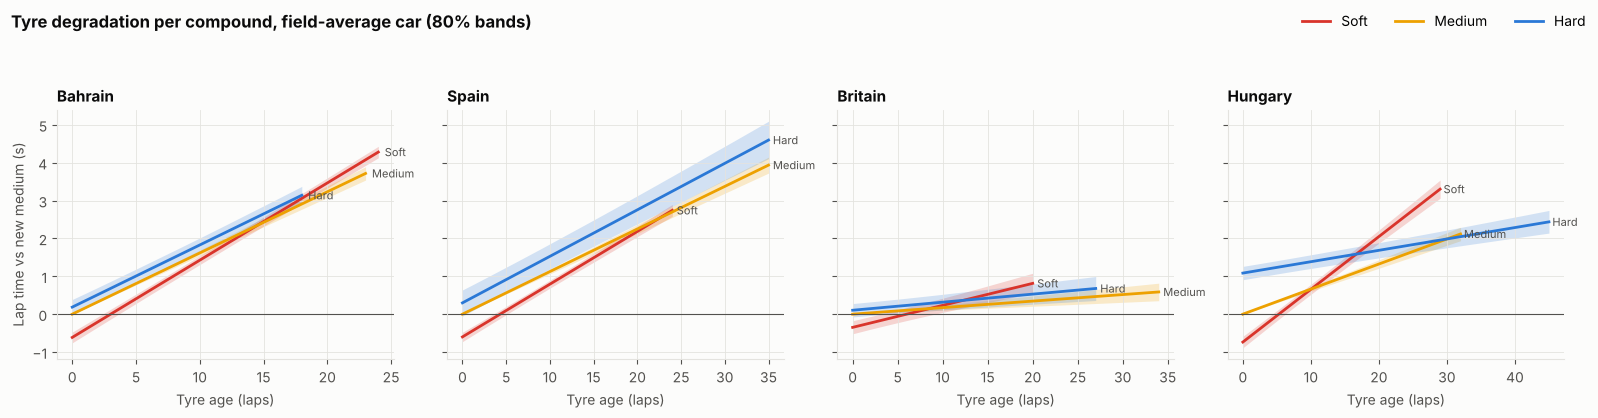

In [6]:
races = [(1, "Bahrain"), (6, "Spain"), (10, "Britain"), (13, "Hungary")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
for ax, (rnd, name) in zip(axes, races):
    race_laps = laps[laps["RoundNumber"] == rnd]
    for comp, color in COMPOUND_COLORS.items():
        used = race_laps.loc[race_laps["Compound"] == comp, "TyreLife"]
        if used.empty:
            continue
        curve = deg_curve(full, rnd, comp, np.arange(0, used.max() + 1))
        ax.fill_between(curve["TyreLife"], curve["lo"], curve["hi"], color=color, alpha=0.2, linewidth=0)
        ax.plot(curve["TyreLife"], curve["mean"], color=color, linewidth=2, label=comp.title())
        ax.text(curve["TyreLife"].iloc[-1] + 0.5, curve["mean"].iloc[-1], comp.title(),
                color=INK_2, fontsize=8, va="center")
    ax.axhline(0, color=INK_2, linewidth=0.8)
    ax.set_title(name, loc="left")
    ax.set_xlabel("Tyre age (laps)")
axes[0].set_ylabel("Lap time vs new medium (s)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=3, frameon=False)
fig.suptitle("Tyre degradation per compound, field-average car (80% bands)", x=0.01, ha="left",
             fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(FIG_DIR / "deg_curves.png")
plt.show()

## Extrapolation: XGBoost vs Bayesian vs actual on `long_tyre`

Both models are trained only on tyre age ≤ 15 laps. Left: mean signed error by
tyre age (positive = predicted too slow). Right: one long stint, actual laps vs
both models.

/tmp/ipykernel_2328/1205279933.py:18: PerformanceWarning: indexing past lexsort depth may impact performance.
  stint = test.set_index(stint_key).loc[longest].reset_index()


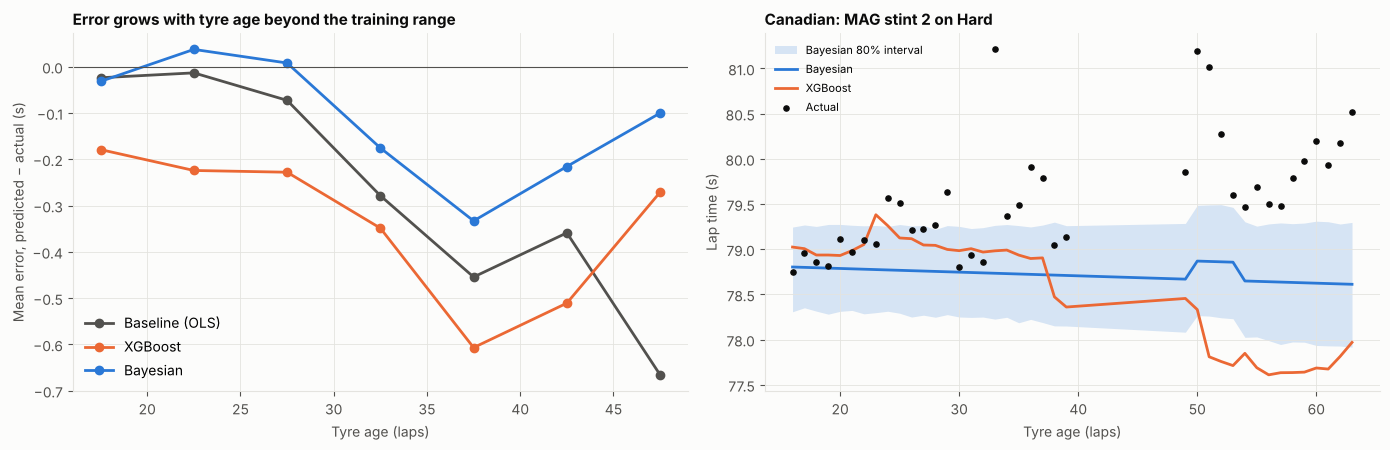

,Baseline (OLS),XGBoost,Bayesian
TyreLife,,,
"(15, 20]",-0.024,-0.179,-0.032
"(20, 25]",-0.013,-0.224,0.037
"(25, 30]",-0.073,-0.228,0.008
"(30, 35]",-0.279,-0.349,-0.176
"(35, 40]",-0.454,-0.607,-0.333
"(40, 45]",-0.359,-0.511,-0.216
"(45, 50]",-0.666,-0.271,-0.100


In [7]:
train, test = SPLITS["long_tyre"](laps)
xgb_pred = predict_xgboost(fit_xgboost(train), test)
bayes_pred = predict(split_fits["long_tyre"], test)
base_pred = predict_baseline(fit_baseline(train), test)

bins = np.arange(15, 51, 5)
age_bin = pd.cut(test["TyreLife"], bins)
err = pd.DataFrame({
    "Baseline (OLS)": base_pred - test["lap_s"],
    "XGBoost": xgb_pred - test["lap_s"],
    "Bayesian": bayes_pred.mean - test["lap_s"],
}).groupby(age_bin, observed=True).mean()
mids = [iv.mid for iv in err.index]

# Longest single stint in the test set, for the right panel.
stint_key = ["RoundNumber", "Driver", "Stint"]
longest = test.groupby(stint_key)["TyreLife"].max().idxmax()
stint = test.set_index(stint_key).loc[longest].reset_index()
idx = test.index[(test[stint_key] == pd.Series(longest, index=stint_key)).all(axis=1)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
for model, color in MODEL_COLORS.items():
    ax1.plot(mids, err[model], marker="o", color=color, linewidth=2, label=model)
ax1.axhline(0, color=INK_2, linewidth=0.8)
ax1.set_xlabel("Tyre age (laps)")
ax1.set_ylabel("Mean error, predicted − actual (s)")
ax1.set_title("Error grows with tyre age beyond the training range", loc="left")
ax1.legend(frameon=False)

x = test.loc[idx, "TyreLife"]
ax2.fill_between(x, bayes_pred.lo[idx], bayes_pred.hi[idx], color=MODEL_COLORS["Bayesian"], alpha=0.18,
                 linewidth=0, label="Bayesian 80% interval")
ax2.plot(x, bayes_pred.mean[idx], color=MODEL_COLORS["Bayesian"], linewidth=2, label="Bayesian")
ax2.plot(x, xgb_pred[idx], color=MODEL_COLORS["XGBoost"], linewidth=2, label="XGBoost")
ax2.scatter(x, test.loc[idx, "lap_s"], color=INK, s=14, zorder=3, label="Actual")
rnd, drv, st = longest
ax2.set_title(f"{event[rnd]}: {drv} stint {st} on {stint['Compound'].iloc[0].title()}", loc="left")
ax2.set_xlabel("Tyre age (laps)")
ax2.set_ylabel("Lap time (s)")
ax2.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "xgb_vs_bayes_long_tyre.png")
plt.show()
err.round(3)

### Error by tyre age on `long_tyre`

Aggregate MAE is close for all three models, so the extrapolation claim rests on
how error grows with tyre age. Mean error is predicted − actual (positive =
predicted too slow).

In [8]:
by_age = error_by_tyre_age(laps, split_fits["long_tyre"])
by_age.to_csv(FIG_DIR / "long_tyre_by_age.csv", index=False)
wide = by_age.pivot(index="bucket", columns="model", values=["mae_s", "mean_error_s"])
wide = wide.reindex(["16-20", "21-30", "31-40", "40+"])
n = by_age.groupby("bucket")["n"].first().reindex(wide.index)
md_table = pd.DataFrame({
    "Tyre age": wide.index, "Laps": n.to_numpy(),
    **{f"MAE {m}": wide[("mae_s", m)].round(3).to_numpy() for m in ["baseline", "xgboost", "bayes"]},
    **{f"Mean error {m}": wide[("mean_error_s", m)].round(3).to_numpy() for m in ["baseline", "xgboost", "bayes"]},
})
(FIG_DIR / "long_tyre_by_age.md").write_text(md_table.to_markdown(index=False) + "\n")
md_table

,Tyre age,Laps,MAE baseline,MAE xgboost,MAE bayes,Mean error baseline,Mean error xgboost,Mean error bayes
0,16-20,2433,0.468,0.429,0.443,-0.024,-0.179,-0.032
1,21-30,2291,0.523,0.507,0.524,-0.036,-0.226,0.026
2,31-40,708,0.662,0.712,0.615,-0.332,-0.427,-0.223
3,40+,107,0.882,1.067,0.772,-0.652,-0.555,-0.246


## Leclerc, Hungary 2022: hard stint, laps 41–53

Full-data fit, so these laps are in the training data: this checks fit, not
forecasting. Dots are actual laps; the line and band are the model's mean and
80% prediction interval.

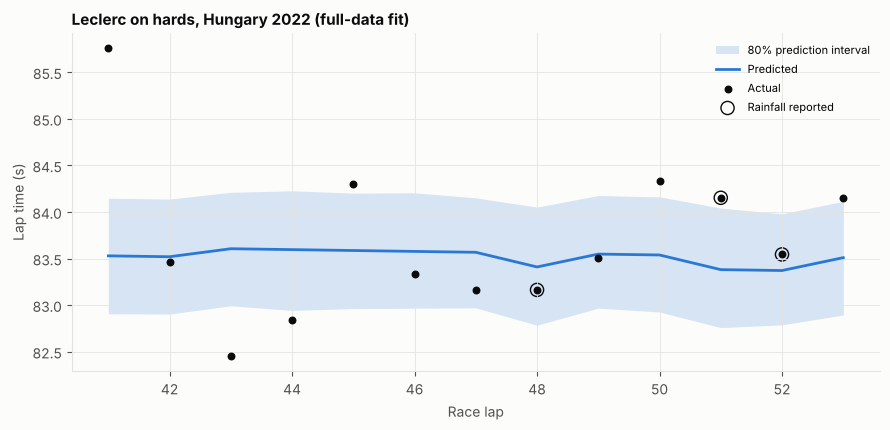

,lap,TyreLife,actual,predicted,lo,hi
8349,41,2,85.755,83.529,82.907,84.148
8350,42,3,83.462,83.519,82.904,84.138
8351,43,4,82.456,83.605,82.993,84.211
8352,44,5,82.839,83.595,82.943,84.227
8353,45,6,84.300,83.586,82.963,84.202
8354,46,7,83.335,83.576,82.967,84.206
8355,47,8,83.158,83.567,82.971,84.151
8356,48,9,83.163,83.409,82.784,84.052
8357,49,10,83.509,83.548,82.967,84.176
8358,50,11,84.334,83.538,82.926,84.162


In [9]:
lec = laps[(laps["RoundNumber"] == 13) & (laps["Driver"] == "LEC") & laps["race_lap"].between(41, 53)]
lec_pred = predict(full, lec)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.fill_between(lec["race_lap"], lec_pred.lo, lec_pred.hi, color=COMPOUND_COLORS["HARD"], alpha=0.18,
                linewidth=0, label="80% prediction interval")
ax.plot(lec["race_lap"], lec_pred.mean, color=COMPOUND_COLORS["HARD"], linewidth=2, label="Predicted")
ax.scatter(lec["race_lap"], lec["lap_s"], color=INK, s=22, zorder=3, label="Actual")
rain = lec[lec["Rainfall"]]
ax.scatter(rain["race_lap"], rain["lap_s"], facecolors="none", edgecolors=INK, s=90, linewidths=1,
           label="Rainfall reported")
ax.set_xlabel("Race lap")
ax.set_ylabel("Lap time (s)")
ax.set_title("Leclerc on hards, Hungary 2022 (full-data fit)", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "leclerc_hungary_hard.png")
plt.show()
pd.DataFrame({"lap": lec["race_lap"], "TyreLife": lec["TyreLife"], "actual": lec["lap_s"],
              "predicted": lec_pred.mean, "lo": lec_pred.lo, "hi": lec_pred.hi}).round(3)

## Ferrari's compound terms at Hungary (full data)

Reported only; interpreted in Phase 6. `team_compound` is Ferrari's deviation
from the field at this race (medium = 0), `field_compound` the field's offset,
`total` their sum, and `team_deg_s_per_lap` Ferrari's season deg vs the field.

In [10]:
team_compound_summary(full, "Ferrari", 13).round(3)

,team,RoundNumber,compound,term,mean,lo,hi
0,Ferrari,13,SOFT,team_compound,-0.004,-0.145,0.143
1,Ferrari,13,SOFT,field_compound,-0.737,-0.888,-0.585
2,Ferrari,13,SOFT,total,-0.741,-0.949,-0.533
3,Ferrari,13,SOFT,team_deg_s_per_lap,0.008,0.004,0.012
4,Ferrari,13,MEDIUM,team_compound,0.000,0.000,0.000
5,Ferrari,13,MEDIUM,field_compound,0.000,0.000,0.000
6,Ferrari,13,MEDIUM,total,0.000,0.000,0.000
7,Ferrari,13,MEDIUM,team_deg_s_per_lap,0.007,0.004,0.009
8,Ferrari,13,HARD,team_compound,0.132,-0.012,0.280
9,Ferrari,13,HARD,field_compound,1.084,0.909,1.262


### Confounding check: Leclerc's stint vs Ferrari's hard term

Leclerc's stint 3 is Ferrari's only hard stint at Hungary, so his stint effect
and `team_compound[Ferrari, hard, Hungary]` are fitted from the same laps.

In [11]:
pd.Series(stint_team_confounding(full, 13, "LEC", 3, "Ferrari", "HARD")).round(3)

correlation          -0.359
team_compound_mean    0.132
team_compound_lo     -0.012
team_compound_hi      0.280
stint_effect_mean     0.087
stint_effect_lo      -0.093
stint_effect_hi       0.267
sum_mean              0.219
sum_lo                0.033
sum_hi                0.407
dtype: float64

## Flags: hard degrading faster than soft, or negative degradation

Field-average linear deg per race and compound (s/lap). Flagged, not forced.

In [12]:
flags = deg_by_race(full).assign(Event=lambda d: d["RoundNumber"].map(event))
flagged = flags[flags["negative"] | flags["hard_faster_than_soft"]]
flagged.round(3)

,RoundNumber,compound,mean,lo,hi,p_negative,p_hard_gt_soft,negative,hard_faster_than_soft,Event
5,2,HARD,-0.001,-0.010,0.008,0.557,0.065,True,False,Saudi Arabian
8,3,HARD,-0.003,-0.012,0.005,0.706,0.062,True,False,Australian
9,5,SOFT,-0.000,-0.029,0.029,0.501,0.551,True,True,Miami
10,5,MEDIUM,0.003,-0.005,0.011,0.344,0.551,False,True,Miami
11,5,HARD,0.003,-0.004,0.010,0.277,0.551,False,True,Miami
48,21,SOFT,0.056,0.050,0.062,0.000,0.973,False,True,São Paulo
49,21,MEDIUM,0.068,0.063,0.074,0.000,0.973,False,True,São Paulo
50,21,HARD,0.110,0.074,0.145,0.000,0.973,False,True,São Paulo
